# Chapter 10 — Intro to Convolutional Neural Networks: Reusing Weights in Multiple Places
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

A fully connected layer gives every pixel its own private weight for every hidden unit. But the *same* pattern — an edge, a corner, a curve — can appear **anywhere** in an image.
Relearning "what an edge looks like" separately at every position is wasteful and fragile. The **convolutional layer** fixes this with one idea: **reuse the same small set of weights at every location** (weight sharing).

**Roadmap**
1. Convolution by hand: a filter slides over an image (edge detection)
2. A convolutional layer with many filters, in vectorized NumPy
3. Backpropagation through a convolution (with a gradient check)
4. Training a CNN on digits and comparing with a dense network of similar size
5. What the learned filters look like
6. Robustness: shifting the image

> Data: the 8×8 scikit-learn digit images (the book uses 28×28 MNIST; same ideas, much smaller images so everything runs in seconds on a CPU). Code and experiments are my own.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.datasets import load_digits

os.makedirs('outputs', exist_ok=True)
np.set_printoptions(precision=3, suppress=True)

digits = load_digits()
X_all, y_all = digits.data / 16.0, digits.target
order = np.random.default_rng(0).permutation(len(X_all))
Xtr, ytr = X_all[order[:1200]], y_all[order[:1200]]
Xte, yte = X_all[order[1200:]], y_all[order[1200:]]
Ytr = np.eye(10)[ytr]
print(Xtr.shape, Xte.shape)

(1200, 64) (597, 64)


## 1. Convolution by hand

A **filter** (kernel) is a small grid of weights, e.g. $3\times3$. To **convolve**, place it on the image, multiply element-wise with the pixels underneath, sum the nine products into one number, then slide one pixel
and repeat. The output is a new image (a **feature map**) that is bright wherever the image looks like the filter.

$$\text{out}[i,j]=\sum_{a=0}^{k-1}\sum_{b=0}^{k-1} K[a,b]\;\text{img}[i+a,\,j+b].$$

(Strictly this is *cross-correlation*; deep-learning libraries and the book call it convolution. Flipping the kernel changes nothing about what can be learned.)
For an $n\times n$ image and a $k\times k$ filter with no padding, the output is $(n-k+1)\times(n-k+1)$; here $8-3+1=6$.

Two hand-made filters — a vertical-edge detector and a horizontal-edge detector — applied to a digit:

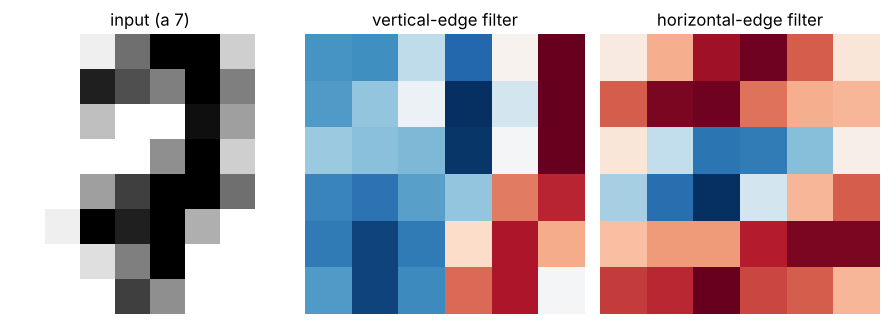

feature-map shape: (6, 6)


In [2]:
def conv2d_loop(img, K):
    # Direct implementation of the formula: slow but transparent
    k = K.shape[0]; n = img.shape[0] - k + 1
    out = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            out[i, j] = np.sum(K * img[i:i + k, j:j + k])
    return out

vertical   = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], float)
horizontal = vertical.T

img = Xtr[np.where(ytr == 7)[0][0]].reshape(8, 8)
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
axes[0].imshow(img, cmap='gray_r'); axes[0].set_title('input (a 7)')
axes[1].imshow(conv2d_loop(img, vertical), cmap='RdBu'); axes[1].set_title('vertical-edge filter')
axes[2].imshow(conv2d_loop(img, horizontal), cmap='RdBu'); axes[2].set_title('horizontal-edge filter')
for a in axes: a.axis('off')
plt.tight_layout(); plt.savefig('outputs/hand_filters.png', dpi=110); plt.show()
print("feature-map shape:", conv2d_loop(img, vertical).shape)

**Reading the output.** The vertical filter responds strongly (red/blue extremes) along the vertical stroke of the 7; the horizontal filter responds along the top bar. The same nine weights examine every position.
Using it as a layer means we do **not hand-design** filters: we let gradient descent learn them.

## 2. A convolutional layer with many filters, vectorized

A layer has $F$ filters. Each gives one feature map, so the layer's output has shape $6\times6\times F$. Looping over positions in Python is slow, so we use the **im2col** trick:
extract every $3\times3$ patch of the image as a row of a matrix, then the whole convolution becomes **one matrix product**.

- `patches`: shape (batch, 36 positions, 9 pixels)
- filters $K$: shape (9, F)
- `feature maps = patches @ K` → (batch, 36, F)

Number of weights: a conv layer with $F$ filters has only $9F$ weights **regardless of the image size**; a dense layer with 64 inputs and the same number of outputs would need $64\cdot36F$.

In [3]:
def extract_patches(X, k=3):
    imgs = X.reshape(-1, 8, 8)
    win = sliding_window_view(imgs, (k, k), axis=(1, 2))        # (batch, 6, 6, 3, 3)
    return win.reshape(len(X), (8 - k + 1) ** 2, k * k)          # (batch, 36, 9)

# check the vectorized version against the explicit loop
P = extract_patches(img.reshape(1, 64))
vec = (P @ vertical.reshape(9, 1)).reshape(6, 6)
print("vectorized == loop:", np.allclose(vec, conv2d_loop(img, vertical)))

F = 8
print(f"weights in a conv layer with {F} filters: {9 * F}   vs a dense layer producing the same {36 * F} outputs: {64 * 36 * F}")

vectorized == loop: True
weights in a conv layer with 8 filters: 72   vs a dense layer producing the same 288 outputs: 18432


## 3. Backpropagation through a convolution

The network: patches → conv (filters $K$, $9\times F$) → ReLU → flatten ($36F$ numbers) → dense layer $W$ ($36F\times10$) → softmax with cross-entropy (Chapter 9).

Backward pass, with output delta $\boldsymbol\delta_{\text{out}}=\hat{\mathbf p}-\mathbf y$:

1. dense layer: $\nabla W=\mathbf h^{\top}\boldsymbol\delta_{\text{out}}$, and the delta reaching the flattened features is $\boldsymbol\delta_{\text{out}}W^{\top}$,
2. ReLU: multiply by $\operatorname{relu}'(\mathbf z)$ (this is a delta for **each position** of each feature map),
3. conv layer: each filter weight was used at **all 36 positions**, so its gradient is the **sum over positions** of (delta at that position × the pixel that weight touched):
$$\nabla K=\sum_{\text{positions}}\text{patch}^{\top}\,\delta .$$
That sum is exactly what the matrix product `patches.T @ delta` computes. Weight sharing means gradients from every location are *added*.

We verify with a numerical gradient check.

In [4]:
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True); E = np.exp(Z); return E / E.sum(axis=1, keepdims=True)

def cnn_forward(X, K, W):
    P = extract_patches(X)                       # (B, 36, 9)
    Z = P @ K                                    # (B, 36, F)
    Hh = np.maximum(0, Z)
    logits = Hh.reshape(len(X), -1) @ W          # flatten -> dense
    return P, Z, Hh, logits

def cnn_grads(X, T, K, W):
    P, Z, Hh, logits = cnn_forward(X, K, W)
    B, F = len(X), K.shape[1]
    d_out = (softmax(logits) - T) / B
    gW = Hh.reshape(B, -1).T @ d_out
    d_h = (d_out @ W.T).reshape(B, 36, F) * (Z > 0)
    gK = np.einsum('bpi,bpf->if', P, d_h)        # sum over batch AND over positions
    return gK, gW

def ce_loss(X, T, K, W):
    return -np.mean(np.sum(T * np.log(softmax(cnn_forward(X, K, W)[3]) + 1e-12), axis=1))

rng = np.random.default_rng(1)
Xg, Tg = Xtr[:6], Ytr[:6]
Kg = rng.normal(0, 0.3, (9, 3)); Wg = rng.normal(0, 0.1, (36 * 3, 10))
gK, gW = cnn_grads(Xg, Tg, Kg, Wg)

def numeric(A, loss, h=1e-6):
    g = np.zeros_like(A)
    for idx in np.ndindex(*A.shape):
        Ap, Am = A.copy(), A.copy(); Ap[idx] += h; Am[idx] -= h
        g[idx] = (loss(Ap) - loss(Am)) / (2 * h)
    return g
nK = numeric(Kg, lambda K: ce_loss(Xg, Tg, K, Wg))
nW = numeric(Wg, lambda W: ce_loss(Xg, Tg, Kg, W))
print("max |analytic - numeric| for filters K :", np.abs(gK - nK).max())
print("max |analytic - numeric| for dense W   :", np.abs(gW - nW).max())

max |analytic - numeric| for filters K : 3.823820982074011e-10
max |analytic - numeric| for dense W   : 4.809919407211538e-10


**Reading the output.** Both differences are tiny (floating-point level), so the weight-sharing gradient — summing the contribution of every position — is correct.

## 4. Training a CNN and comparing it with a dense network

Two models trained with the same mini-batch SGD, the same loss (softmax + cross-entropy) and several seeds:

- **CNN**: 8 filters of $3\times3$ → ReLU → dense to 10 classes (`72 + 2880 = 2952` weights counting filters and the output layer),
- **Dense**: 64 → 40 hidden ReLU → 10 (`2560 + 400 = 2960` weights), chosen to have **about the same number of weights**.

In [5]:
def train_cnn(seed, F=8, lr=0.05, epochs=40, batch=32):
    rng = np.random.default_rng(seed)
    K = rng.normal(0, np.sqrt(2 / 9), (9, F)); W = rng.normal(0, np.sqrt(2 / (36 * F)), (36 * F, 10))
    for ep in range(epochs):
        idx = rng.permutation(len(Xtr))
        for s in range(0, len(idx), batch):
            b = idx[s:s + batch]
            gK, gW = cnn_grads(Xtr[b], Ytr[b], K, W)
            K -= lr * gK; W -= lr * gW
    return K, W

def train_dense(seed, H=40, lr=0.1, epochs=40, batch=32):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, np.sqrt(2 / 64), (64, H)); W2 = rng.normal(0, np.sqrt(2 / H), (H, 10))
    for ep in range(epochs):
        idx = rng.permutation(len(Xtr))
        for s in range(0, len(idx), batch):
            b = idx[s:s + batch]; z = Xtr[b] @ W1; l1 = np.maximum(0, z)
            d2 = (softmax(l1 @ W2) - Ytr[b]) / len(b); d1 = (d2 @ W2.T) * (z > 0)
            W2 -= lr * l1.T @ d2; W1 -= lr * Xtr[b].T @ d1
    return W1, W2

cnn_predict   = lambda X, m: cnn_forward(X, *m)[3].argmax(1)
dense_predict = lambda X, m: (np.maximum(0, X @ m[0]) @ m[1]).argmax(1)

seeds = range(5)
cnn_models   = [train_cnn(s) for s in seeds]
dense_models = [train_dense(s) for s in seeds]

acc = lambda pred_fn, models, X, y: np.array([np.mean(pred_fn(X, m) == y) for m in models])
c_tr, c_te = acc(cnn_predict, cnn_models, Xtr, ytr), acc(cnn_predict, cnn_models, Xte, yte)
d_tr, d_te = acc(dense_predict, dense_models, Xtr, ytr), acc(dense_predict, dense_models, Xte, yte)

print("model | weights | train acc        | test acc")
print(f"CNN   | {72 + 2880:7d} | {c_tr.mean():.3f} (+/- {c_tr.std():.3f}) | {c_te.mean():.3f} (+/- {c_te.std():.3f})")
print(f"Dense | {2560 + 400:7d} | {d_tr.mean():.3f} (+/- {d_tr.std():.3f}) | {d_te.mean():.3f} (+/- {d_te.std():.3f})")

model | weights | train acc        | test acc
CNN   |    2952 | 0.982 (+/- 0.006) | 0.962 (+/- 0.007)
Dense |    2960 | 0.987 (+/- 0.002) | 0.969 (+/- 0.004)


**Reading the output.** With roughly equal numbers of weights, the two models reach very similar accuracy (CNN about 0.96, dense about 0.97 on the test set). The dense network is even slightly ahead, by about as much as the seed-to-seed spread. That is honest and expected: 8x8 digits are tiny, centred and easy, so there is little for weight sharing to exploit. The advantage of convolution shows up on larger images where a dense layer would need an enormous number of weights.

## 5. What the learned filters look like

Each of the 8 learned filters is a $3\times3$ grid of weights. Red = the filter likes bright pixels there, blue = it likes dark pixels there. Below: the filters of the first CNN, and
the feature maps that two of them produce for one test image.

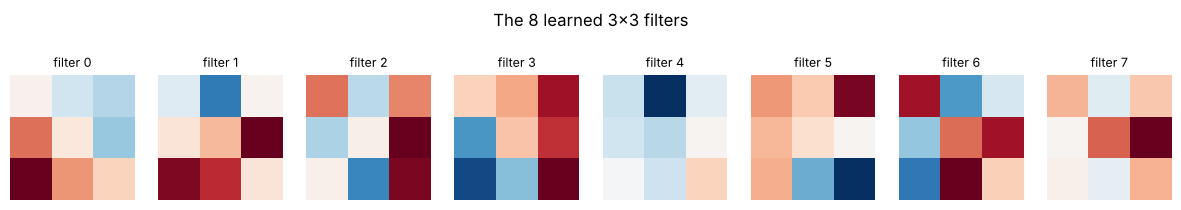

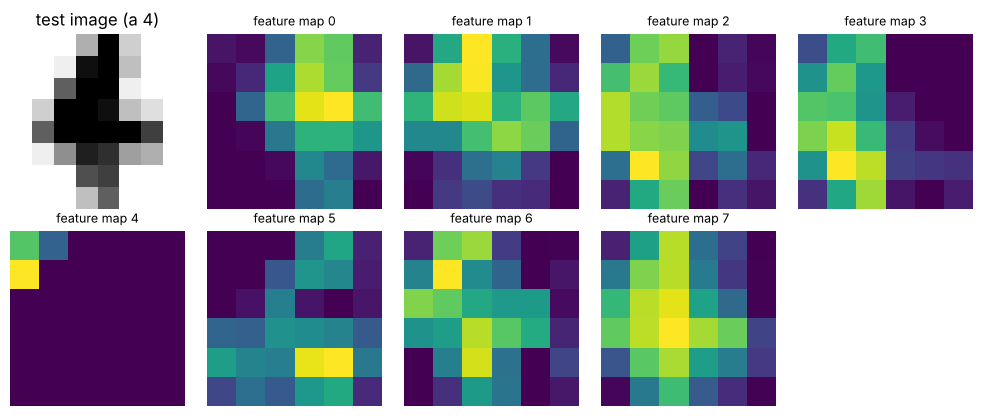

In [6]:
K, W = cnn_models[0]
fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for f, ax in enumerate(axes):
    v = np.abs(K[:, f]).max()
    ax.imshow(K[:, f].reshape(3, 3), cmap='RdBu_r', vmin=-v, vmax=v); ax.set_title(f'filter {f}', fontsize=9); ax.axis('off')
plt.suptitle('The 8 learned 3x3 filters', y=1.08); plt.tight_layout(); plt.savefig('outputs/learned_filters.png', dpi=110, bbox_inches='tight'); plt.show()

i = np.where(yte == 4)[0][0]
Z = np.maximum(0, cnn_forward(Xte[i:i + 1], K, W)[1])[0].reshape(6, 6, 8)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
axes[0, 0].imshow(Xte[i].reshape(8, 8), cmap='gray_r'); axes[0, 0].set_title('test image (a 4)')
for f, ax in zip(range(8), axes.ravel()[1:9]):
    ax.imshow(Z[:, :, f], cmap='viridis'); ax.set_title(f'feature map {f}', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout(); plt.savefig('outputs/feature_maps.png', dpi=110); plt.show()

**Reading the output.** Learned filters are small local pattern detectors (they are not as clean as the hand-made edge filters, since they were optimized for classifying digits rather than for being interpretable).
Each feature map shows *where* in the image a given pattern is present.

## 6. Robustness: shifting the image

A dense network ties each pixel to a fixed weight, so a digit moved by one pixel looks like a *different input*. A convolutional layer applies the same filters everywhere, so its feature maps simply move along with the digit (equivariance). Does that help the final classification?
(Caution: our CNN has no pooling and uses a dense layer after the flatten, so we should not expect full shift invariance. We test it anyway to see what happens.)

We test **both trained models, without retraining,** on test images shifted by 1 pixel in a random direction (with zero padding).

test accuracy under a 1-pixel shift (mean of 5 seeds)
shift (dx,dy) | (0, 0)   | (1, 0)   | (-1, 0)  | (0, 1)   | (0, -1)  | mean of the 4 shifted
CNN           |    0.962 |    0.441 |    0.408 |    0.455 |    0.419 | 0.431
Dense         |    0.969 |    0.422 |    0.437 |    0.418 |    0.399 | 0.419


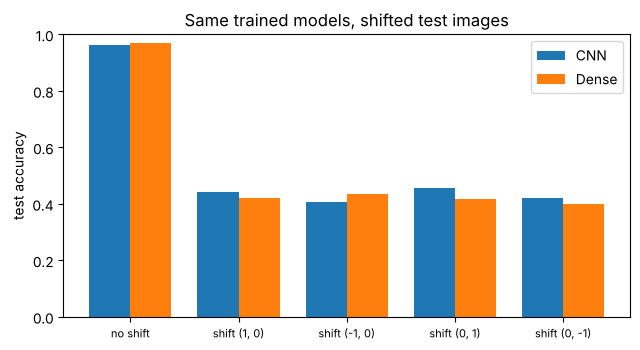

In [7]:
def shift(X, dx, dy):
    imgs = X.reshape(-1, 8, 8); out = np.zeros_like(imgs)
    xs, xd = (slice(dx, None), slice(0, 8 - dx)) if dx >= 0 else (slice(0, 8 + dx), slice(-dx, None))
    ys, yd = (slice(dy, None), slice(0, 8 - dy)) if dy >= 0 else (slice(0, 8 + dy), slice(-dy, None))
    out[:, ys, xs] = imgs[:, yd, xd]
    return out.reshape(len(X), 64)

shifts = [(0, 0), (1, 0), (-1, 0), (0, 1), (0, -1)]
rows = {}
for name, fn, models in [('CNN', cnn_predict, cnn_models), ('Dense', dense_predict, dense_models)]:
    rows[name] = [acc(fn, models, shift(Xte, dx, dy), yte).mean() for dx, dy in shifts]

print("test accuracy under a 1-pixel shift (mean of 5 seeds)")
print("shift (dx,dy) |", " | ".join(f"{str(s):8s}" for s in shifts), "| mean of the 4 shifted")
for name, r in rows.items():
    print(f"{name:13s} |", " | ".join(f"{v:8.3f}" for v in r), f"| {np.mean(r[1:]):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
w = 0.38; xs = np.arange(len(shifts))
ax.bar(xs - w / 2, rows['CNN'], w, label='CNN'); ax.bar(xs + w / 2, rows['Dense'], w, label='Dense')
ax.set_xticks(xs); ax.set_xticklabels([f'shift {s}' if s != (0, 0) else 'no shift' for s in shifts], fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel('test accuracy'); ax.legend(); ax.set_title('Same trained models, shifted test images')
plt.tight_layout(); plt.savefig('outputs/shift_robustness.png', dpi=110); plt.show()

**Reading the output.** Both models collapse under a one-pixel shift: from about 0.96–0.97 to about 0.42–0.43 on average, and the CNN is **not** meaningfully more robust than the dense network (0.431 vs 0.419, within noise).
This is an honest negative result, and it has a clear explanation. Convolution is *shift-equivariant* (the feature maps move with the digit), but our network then **flattens** the feature maps and feeds them to a dense layer
that assigns a different weight to every position, so the final decision again depends on exactly where things are. Real CNNs get closer to shift *invariance* by adding **pooling** (e.g. max-pooling, which keeps only the strongest
response in a neighbourhood) and by stacking many conv layers, or by training with shifted examples (data augmentation). Weight sharing by itself saves parameters and finds local patterns; it does not by itself make a classifier shift-proof.

## Summary

| Idea | What it is | Key formula / fact |
|---|---|---|
| Filter / kernel | small grid of weights reused at every position | $\text{out}[i,j]=\sum K[a,b]\,\text{img}[i+a,j+b]$ |
| Feature map | the filter's response at every position | size $(n-k+1)^2$ without padding |
| Weight sharing | same weights at all positions → far fewer weights | conv layer: $k^2F$ weights, independent of image size |
| im2col | turn all patches into a matrix → one matrix product | `patches @ K` |
| Backprop through conv | gradients from all positions are **summed** | $\nabla K=\sum_{\text{pos}}\text{patch}^{\top}\delta$ |
| Local patterns | filters detect edges/corners anywhere | feature maps move with the object (equivariance); invariance needs pooling |

**Key takeaway:** a convolutional layer is a dense layer with a strong built-in assumption — *the same pattern can occur anywhere* — implemented by reusing a few weights at every location. It needs far fewer
parameters in the convolutional layer and shares what it learns across positions; in our small experiment it matched, but did not beat, a dense network of equal size, and shift robustness required more than
convolution alone (pooling, depth or augmentation).